In [ ]:
import pandas as pd
import matplotlib.pyplot as plt



In [ ]:
df=pd.read_csv("netflix_titles.csv")

In [ ]:
print(df.head())

  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1  September 24, 2021          2021  TV-MA  2 Seasons   
2  September 24, 2021        

In [ ]:
df.shape

(8807, 12)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [ ]:
print(df.isnull().sum())

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


In [ ]:
df=df.dropna(subset=["rating","duration"])
print(len(df))
print(df[["rating","duration"]].isnull().sum())

8800
rating      0
duration    0
dtype: int64


In [ ]:
print(df["rating"].str.contains("min", na=False).sum())

0


In [ ]:
df["director"]=df["director"].fillna("Unknown")
df["country"]=df["country"].fillna("Unknown")
df["cast"]=df["cast"].fillna("Unknown")


In [ ]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,10
release_year,0
rating,4
duration,3


In [ ]:
print(df["date_added"].head())

0    September 25, 2021
1    September 24, 2021
2    September 24, 2021
3    September 24, 2021
4    September 24, 2021
Name: date_added, dtype: object


In [ ]:
df["date_added"]=pd.to_datetime(df["date_added"].str.strip())

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8807 non-null   object        
 1   type          8807 non-null   object        
 2   title         8807 non-null   object        
 3   director      6173 non-null   object        
 4   cast          7982 non-null   object        
 5   country       7976 non-null   object        
 6   date_added    8797 non-null   datetime64[ns]
 7   release_year  8807 non-null   int64         
 8   rating        8803 non-null   object        
 9   duration      8804 non-null   object        
 10  listed_in     8807 non-null   object        
 11  description   8807 non-null   object        
dtypes: datetime64[ns](1), int64(1), object(10)
memory usage: 825.8+ KB


In [ ]:
df["year_added"] = df["date_added"].dt.year
df["month_added"] = df["date_added"].dt.month
print(df[["title", "date_added", "year_added", "month_added"]].head())

                   title date_added  year_added  month_added
0   Dick Johnson Is Dead 2021-09-25      2021.0          9.0
1          Blood & Water 2021-09-24      2021.0          9.0
2              Ganglands 2021-09-24      2021.0          9.0
3  Jailbirds New Orleans 2021-09-24      2021.0          9.0
4           Kota Factory 2021-09-24      2021.0          9.0


In [ ]:
print(df["rating"].str.contains("min", na=False).sum())

0


In [ ]:
print(df["type"].value_counts())

type
Movie      6126
TV Show    2674
Name: count, dtype: int64


In [ ]:
counts = df["year_added"].value_counts()
print(counts.head())
print(counts.idxmax())

year_added
2019.0    2016
2020.0    1879
2018.0    1648
2021.0    1498
2017.0    1185
Name: count, dtype: int64
2019.0


In [ ]:
counts=df["rating"].value_counts()
print(counts.head())


rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
Name: count, dtype: int64


In [ ]:
known = df[df["country"] != "Unknown"]
counts = known["country"].value_counts()
print(counts.head())

country
United States     2815
India              972
United Kingdom     419
Japan              244
South Korea        199
Name: count, dtype: int64


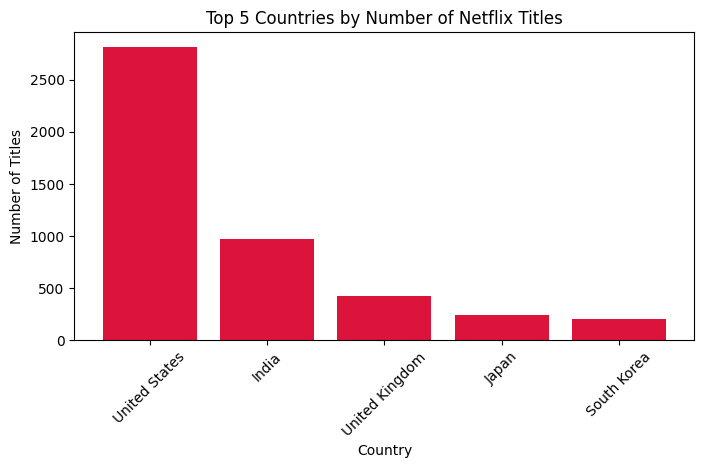

In [ ]:
top5 = counts.head(5)

plt.figure(figsize=(8, 4))
plt.bar(top5.index, top5.values, color="crimson")
plt.title("Top 5 Countries by Number of Netflix Titles")
plt.xlabel("Country")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.show()


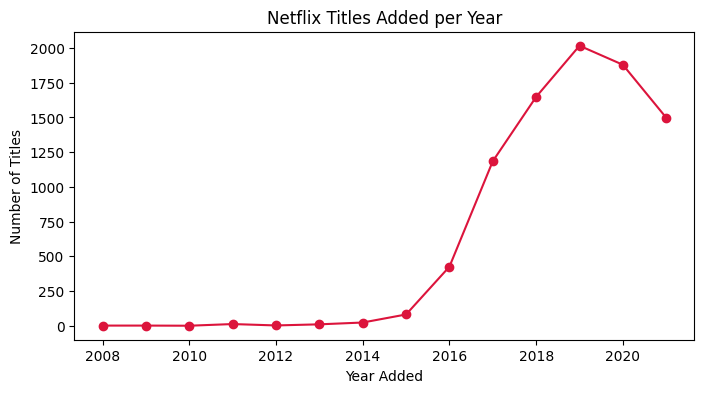

In [ ]:
plt.figure(figsize=(8,4))
plt.plot(per_year.index,per_year.values,marker="o",color="crimson")
plt.title("Netflix Titles Added per Year")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.show()

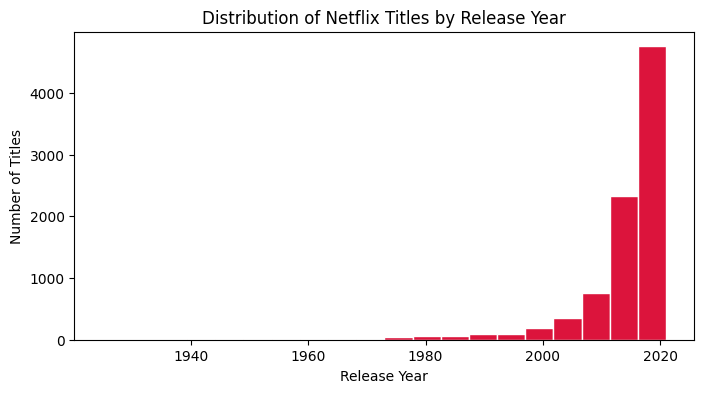

In [54]:
plt.figure(figsize=(8, 4))
plt.hist(df["release_year"], bins=20, color="crimson", edgecolor="white")
plt.title("Distribution of Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.show()